# EN4554 Assignment 2: Neural Networks and CNNs on CIFAR-10

**Name:** Walgampaya H.K.B. 

 **Index number:** 220675T

**GitHub:** https://github.com/HimethW/EN4554-Assignment_2-on-CNNs

I split the 50k CIFAR-10 training images into 45k for training and 5k for validation (with a fixed seed), and normalise each channel using the mean and std of the 45k training images. The test set is only used once, at the end of Task 4. Setting `QUICK_RUN = True` trains everything for just one epoch, which is handy for checking that the notebook runs on Colab.

In [1]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

QUICK_RUN = False
SEED = 0
DATA_DIR = "./data"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def n_epochs(n):
    return 1 if QUICK_RUN else n


set_seed()
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6"]),
})

In [2]:
cifar = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True)
images = torch.from_numpy(cifar.data).permute(0, 3, 1, 2).float() / 255
labels = torch.tensor(cifar.targets)

perm = torch.randperm(len(images), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45_000], perm[45_000:]
MEAN = images[train_idx].mean(dim=(0, 2, 3))
STD = images[train_idx].std(dim=(0, 2, 3))


def normalize(x):
    return (x - MEAN.view(1, 3, 1, 1)) / STD.view(1, 3, 1, 1)


# the whole split lives on the GPU, so batching needs no DataLoader
X_train, y_train = normalize(images[train_idx]).to(device), labels[train_idx].to(device)
X_val, y_val = normalize(images[val_idx]).to(device), labels[val_idx].to(device)
del images, labels


def batches(X, y, batch_size, shuffle=False, gen=None):
    order = torch.randperm(len(X), generator=gen).to(X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), batch_size):
        idx = order[i:i + batch_size]
        yield X[idx], y[idx]


print("train", tuple(X_train.shape), "val", tuple(X_val.shape))
print("mean", MEAN.numpy().round(4), "std", STD.numpy().round(4))

train (45000, 3, 32, 32) val (5000, 3, 32, 32)
mean [0.4912 0.482  0.4464] std [0.2472 0.2436 0.2617]


# Task 1: Backpropagation

## 1(a) Linear, ReLU and softmax cross-entropy

Each layer has two methods. `forward` computes the output and saves what it needs for later. `backward` gets the gradient from the layer above, works out the gradients of its own weights, and passes the gradient down to the layer below. No autograd is used.

Here $dy$ means the gradient of the loss with respect to $y$, and $N$ is the batch size.

| Layer | Forward | Backward |
|---|---|---|
| Linear | $y = xW^\top + b$ | $dW = dy^\top x$, $\;db = $ sum of $dy$ over the batch, $\;dx = dy\,W$ |
| ReLU | $y = \max(0, x)$ | $dx = dy$ where $x > 0$, and $0$ elsewhere |
| Softmax + cross-entropy | $L = -\frac{1}{N}\sum \log(p_\text{true class})$ | $dz = \frac{1}{N}\big(p - \text{onehot}(\text{label})\big)$ |

In the softmax I subtract the largest logit first so `exp` can't overflow. Weights start with Kaiming init (std $= \sqrt{2/d_\text{in}}$) for ReLU, or Xavier init (std $= \sqrt{2/(d_\text{in} + d_\text{out})}$) for the sigmoid network in 1(d).

In [3]:
class Linear:
    def __init__(self, n_in, n_out, init="kaiming", dtype=torch.float32):
        std = math.sqrt(2 / n_in) if init == "kaiming" else math.sqrt(2 / (n_in + n_out))
        self.W = (torch.randn(n_out, n_in, dtype=dtype) * std).to(device)
        self.b = torch.zeros(n_out, dtype=dtype, device=device)

    def forward(self, x):
        self.x = x
        return x @ self.W.T + self.b

    def backward(self, dout):
        self.dW = dout.T @ self.x
        self.db = dout.sum(dim=0)
        return dout @ self.W


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        z = logits - logits.max(dim=1, keepdim=True).values  # log-sum-exp trick
        log_p = z - z.exp().sum(dim=1, keepdim=True).log()
        self.p, self.y = log_p.exp(), y
        self.rows = torch.arange(len(y), device=y.device)
        return -log_p[self.rows, y].mean()

    def backward(self):
        grad = self.p.clone()
        grad[self.rows, self.y] -= 1
        return grad / len(self.y)


class MLP:
    def __init__(self, sizes, activation=ReLU, init="kaiming", dtype=torch.float32):
        self.linears = [Linear(a, b, init, dtype) for a, b in zip(sizes[:-1], sizes[1:])]
        self.layers = []
        for lin in self.linears:
            self.layers += [lin, activation()]
        self.layers.pop()  # the last layer outputs logits
        self.criterion = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.criterion.forward(self.forward(x), y)

    def backward(self):
        grad = self.criterion.backward()
        for layer in reversed(self.layers):
            grad = layer.backward(grad)

    def params(self):
        return [p for lin in self.linears for p in (lin.W, lin.b)]

    def grads(self):
        return [g for lin in self.linears for g in (lin.dW, lin.db)]

## 1(b) Gradient check

I compare my gradients for a 3072 → 512 → 256 → 10 MLP with two references: autograd (the same weights loaded into `nn.Linear` layers) and centred finite differences, $\frac{L(\theta + h) - L(\theta - h)}{2h}$ with $h = 10^{-6}$. Finite differences need two forward passes per weight, so I only check 20 random weights in each tensor. Everything is in float64 because float32 isn't precise enough for finite differences. The relative error is $\|g - \hat g\| \,/\, \max(\|g\|, \|\hat g\|)$.

In [4]:
def rel_error(a, b):
    return ((a - b).norm() / torch.maximum(a.norm(), b.norm())).item()


def autograd_grads(mlp, x, y):
    layers = []
    for lin in mlp.linears:
        layer = nn.Linear(lin.W.shape[1], lin.W.shape[0]).to(device, lin.W.dtype)
        with torch.no_grad():
            layer.weight.copy_(lin.W)
            layer.bias.copy_(lin.b)
        layers += [layer, nn.ReLU()]
    net = nn.Sequential(*layers[:-1])
    F.cross_entropy(net(x), y).backward()
    return [p.grad for p in net.parameters()]


def finite_diff_grads(mlp, x, y, n_entries=20, h=1e-6):
    estimates = []
    for p in mlp.params():
        flat = p.view(-1)
        idx = torch.randperm(flat.numel())[:n_entries]
        est = torch.empty(len(idx), dtype=p.dtype)
        for k, i in enumerate(idx):
            old = flat[i].item()
            flat[i] = old + h
            loss_plus = mlp.loss(x, y).item()
            flat[i] = old - h
            loss_minus = mlp.loss(x, y).item()
            flat[i] = old
            est[k] = (loss_plus - loss_minus) / (2 * h)
        estimates.append((idx, est))
    return estimates


set_seed()
mlp = MLP([3072, 512, 256, 10], dtype=torch.float64)
x, y = X_train[:64].flatten(1).double(), y_train[:64]
mlp.loss(x, y)
mlp.backward()
auto = autograd_grads(mlp, x, y)
numeric = finite_diff_grads(mlp, x, y)

print(f"{'param':<7}{'shape':<14}{'vs autograd':>13}{'allclose':>10}{'vs finite diff':>17}{'allclose':>10}")
for i, (g, a, (idx, est)) in enumerate(zip(mlp.grads(), auto, numeric)):
    name = ("W", "b")[i % 2] + str(i // 2 + 1)
    g_sub = g.view(-1)[idx].cpu()
    print(f"{name:<7}{str(tuple(g.shape)):<14}{rel_error(g, a):>13.1e}{str(torch.allclose(g, a)):>10}"
          f"{rel_error(g_sub, est):>17.1e}{str(torch.allclose(g_sub, est)):>10}")

param  shape           vs autograd  allclose   vs finite diff  allclose
W1     (512, 3072)         6.3e-16      True          1.7e-08      True
b1     (512,)              5.4e-16      True          1.7e-08      True
W2     (256, 512)          8.0e-16      True          2.2e-08      True
b2     (256,)              4.0e-16      True          1.1e-08      True
W3     (10, 256)           7.5e-16      True          1.7e-09      True
b3     (10,)               3.3e-16      True          2.1e-09      True


All the relative errors against autograd are around $10^{-16}$, which is just float64 rounding, so my backward pass gives the same gradients as autograd. Against finite differences the errors are around $10^{-8}$ to $10^{-9}$. They are a bit bigger only because the finite difference is itself an approximation, not because the gradients are wrong. `torch.allclose` is True for every parameter in both checks, so the manual backpropagation is correct.

## 1(c) Training with SGD

The same MLP is trained on the flattened images with plain SGD ($\theta \leftarrow \theta - \eta\, \nabla L$), batch size 128, learning rate 0.05, for 30 epochs. I picked the learning rate by trying a few values and comparing validation accuracy.

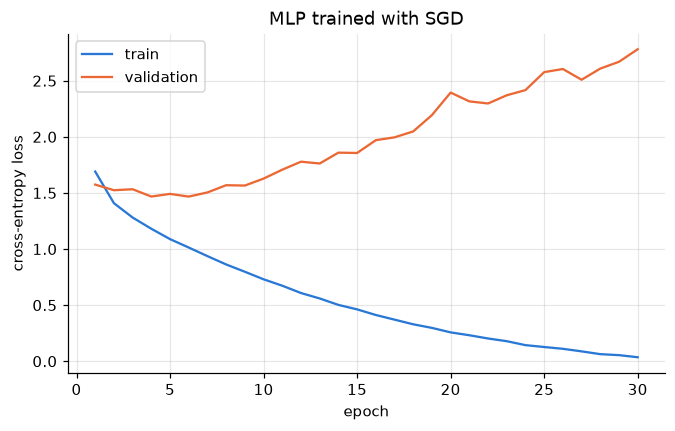

train accuracy 97.29%
validation accuracy 51.14%


In [5]:
def evaluate(mlp, X, y, batch_size=1000):
    loss_sum, correct = 0.0, 0
    for xb, yb in batches(X, y, batch_size):
        logits = mlp.forward(xb.flatten(1))
        loss_sum += mlp.criterion.forward(logits, yb).item() * len(yb)
        correct += (logits.argmax(1) == yb).sum().item()
    return loss_sum / len(X), correct / len(X)


def train_sgd(mlp, epochs, lr, batch_size=128):
    gen = torch.Generator().manual_seed(SEED)
    train_loss, val_loss = [], []
    for _ in range(epochs):
        losses = []
        for xb, yb in batches(X_train, y_train, batch_size, shuffle=True, gen=gen):
            losses.append(mlp.loss(xb.flatten(1), yb).item())
            mlp.backward()
            for p, g in zip(mlp.params(), mlp.grads()):
                p -= lr * g
        train_loss.append(np.mean(losses))
        val_loss.append(evaluate(mlp, X_val, y_val)[0])
    return train_loss, val_loss


set_seed()
mlp = MLP([3072, 512, 256, 10])
train_loss, val_loss = train_sgd(mlp, n_epochs(30), lr=0.05)

epochs = range(1, len(train_loss) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, train_loss, label="train")
plt.plot(epochs, val_loss, label="validation")
plt.xlabel("epoch")
plt.ylabel("cross-entropy loss")
plt.title("MLP trained with SGD")
plt.legend()
plt.show()

print(f"train accuracy {evaluate(mlp, X_train, y_train)[1]:.2%}")
print(f"validation accuracy {evaluate(mlp, X_val, y_val)[1]:.2%}")

The training loss keeps falling to almost zero, but the validation loss is lowest around epochs 4 to 6 (about 1.47) and then climbs to about 2.8. So the MLP starts overfitting after only a few epochs, and by the end it gets 97% of the training images right but only 51% of the validation images. Validation accuracy stays at about 50% after epoch 6 even though the validation loss goes up, because the network becomes more and more confident on the images it gets wrong. An MLP treats an image as a flat list of 3072 numbers and doesn't know which pixels are next to each other, so it ends up memorising the training set instead of learning features that generalise.

## 1(d) Gradient norms at initialisation

I build a 10-layer MLP (3072 → 256 → … → 256 → 10), run one backward pass on 512 images and plot the norm of each layer's weight gradient. This is done once with sigmoid (Xavier init) and once with ReLU (Kaiming init). The sigmoid backward is $dx = dy \cdot \sigma(x)\big(1 - \sigma(x)\big)$.

sigmoid (Xavier init)  layer 1: 1.2e-05   layer 10: 2.3e+00
ReLU (Kaiming init)    layer 1: 4.5e+00   layer 10: 5.9e+00


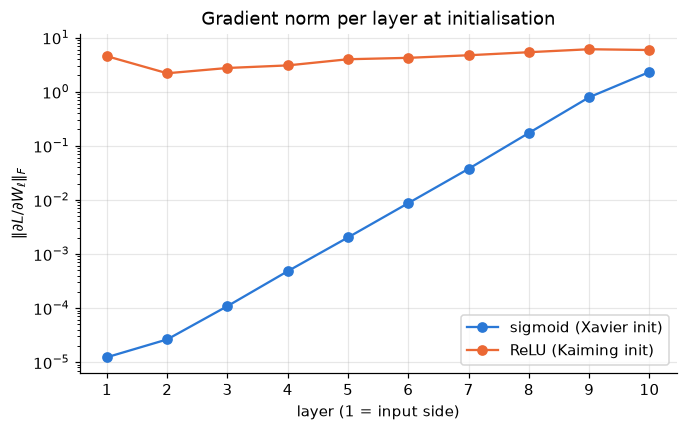

In [6]:
class Sigmoid:
    def forward(self, x):
        self.out = torch.sigmoid(x)
        return self.out

    def backward(self, dout):
        return dout * self.out * (1 - self.out)


def layer_grad_norms(activation, init):
    set_seed()
    mlp = MLP([3072] + [256] * 9 + [10], activation, init)
    mlp.loss(X_train[:512].flatten(1), y_train[:512])
    mlp.backward()
    return [lin.dW.norm().item() for lin in mlp.linears]


plt.figure(figsize=(7, 4))
for name, act, init in [("sigmoid (Xavier init)", Sigmoid, "xavier"), ("ReLU (Kaiming init)", ReLU, "kaiming")]:
    norms = layer_grad_norms(act, init)
    plt.semilogy(range(1, 11), norms, marker="o", label=name)
    print(f"{name:<22} layer 1: {norms[0]:.1e}   layer 10: {norms[-1]:.1e}")
plt.xticks(range(1, 11))
plt.xlabel("layer (1 = input side)")
plt.ylabel(r"$\|\partial L / \partial W_\ell\|_F$")
plt.title("Gradient norm per layer at initialisation")
plt.legend()
plt.show()

With sigmoid, the gradient norm shrinks by about 4x for every layer we go back, from about 2 at layer 10 to about $10^{-5}$ at layer 1, so the first layers would barely learn. This is the vanishing gradient problem: the sigmoid's derivative is at most 0.25, and backpropagation multiplies by it once per layer, so the gradient shrinks exponentially with depth. ReLU's derivative is exactly 1 wherever the unit is active, and Kaiming init keeps the signal about the same size from layer to layer, so its gradient norms stay between about 2 and 6 in every layer. That's why deep networks use ReLU with a matching initialisation instead of sigmoid.